# 02 流量与转化漏斗分析

基于 01 产出的分析数据集（100 万条抽样，清洗后 93.9 万条），回答三个问题：

1. **流量规模**：31 天内 PV / UV / 人均浏览量是多少？
2. **转化漏斗**：浏览 → 收藏/加购 → 购买，各环节转化率多少？流失最严重的环节在哪？
3. **大促效应**：双 12 当天流量与转化有什么变化？

> 本章同时给出等价的 **MySQL 查询语句**（见 `sql/漏斗分析.sql`），用于 SQL 交叉验证。

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
mpl.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110

df = pd.read_csv('data/userbehavior_1m.csv',
                 dtype={'user_id': str, 'item_id': str, 'item_category': str})
df['time'] = pd.to_datetime(df['time'], format='%Y-%m-%d %H')
df['date'] = df['time'].dt.date
# 行为代码 -> 名称（1=浏览 2=购买 3=收藏 4=加购）
df['behavior_type'] = pd.to_numeric(df['behavior_type']).map({1: 'pv', 2: 'buy', 3: 'fav', 4: 'cart'})
df['hour'] = df['time'].dt.hour
# 与 01 保持同一清洗口径：去 geohash 列 + 按行去重
df = df.drop(columns=['user_geohash']).drop_duplicates().reset_index(drop=True)
print('清洗后：', df.shape, ' 用户数：', df['user_id'].nunique())
print('时间范围：', df['time'].min(), '->', df['time'].max())

清洗后： (939270, 7)  用户数： 9929
时间范围： 2014-11-18 00:00:00 -> 2014-12-18 23:00:00


## 一、流量总览

In [2]:
pv = (df['behavior_type'] == 'pv').sum()
uv = df['user_id'].nunique()
buy_uv = df[df['behavior_type'] == 'buy']['user_id'].nunique()
summary = pd.DataFrame({
    '指标': ['总 PV（浏览次数）', 'UV（独立访客）', '人均浏览量', '购买用户数', '购买用户占比'],
    '数值': [f'{pv:,}', f'{uv:,}', f'{pv/uv:.1f}', f'{buy_uv:,}', f'{buy_uv/uv:.1%}']})
summary

,指标,数值
0,总 PV（浏览次数）,"881,841"
1,UV（独立访客）,"9,929"
2,人均浏览量,88.8
3,购买用户数,"3,604"
4,购买用户占比,36.3%


## 二、转化漏斗

**两种口径**：

- **行为次数口径**：各行为发生的总次数之比（受复购/重复浏览影响）；
- **用户数口径**（更接近真实转化）：发生某行为的**独立用户数**之比。

电商经典漏斗为：浏览 →（收藏 或 加购）→ 购买，因为收藏和加购同属"产生兴趣"环节。

In [3]:
# 行为次数口径与用户数口径对齐到同一漏斗
cnt = df['behavior_type'].value_counts()
u_pv = df.loc[df['behavior_type'] == 'pv', 'user_id'].nunique()
u_int = df.loc[df['behavior_type'].isin(['fav', 'cart']), 'user_id'].nunique()
u_buy = df.loc[df['behavior_type'] == 'buy', 'user_id'].nunique()

conv = pd.DataFrame({
    '环节': ['浏览 pv', '兴趣（收藏∪加购）', '购买 buy'],
    '行为次数': [int(cnt['pv']), int(cnt['fav'] + cnt['cart']), int(cnt['buy'])],
    '用户数': [u_pv, u_int, u_buy],
})
conv['用户口径环比转化率'] = ['-', f'{u_int/u_pv:.1%}', f'{u_buy/u_int:.1%}']
conv

,环节,行为次数,用户数,用户口径环比转化率
0,浏览 pv,881841,9925,-
1,兴趣（收藏∪加购）,37589,6939,69.9%
2,购买 buy,19840,3604,51.9%


findfont: Failed to find font weight bold for SimHei, now using 400.


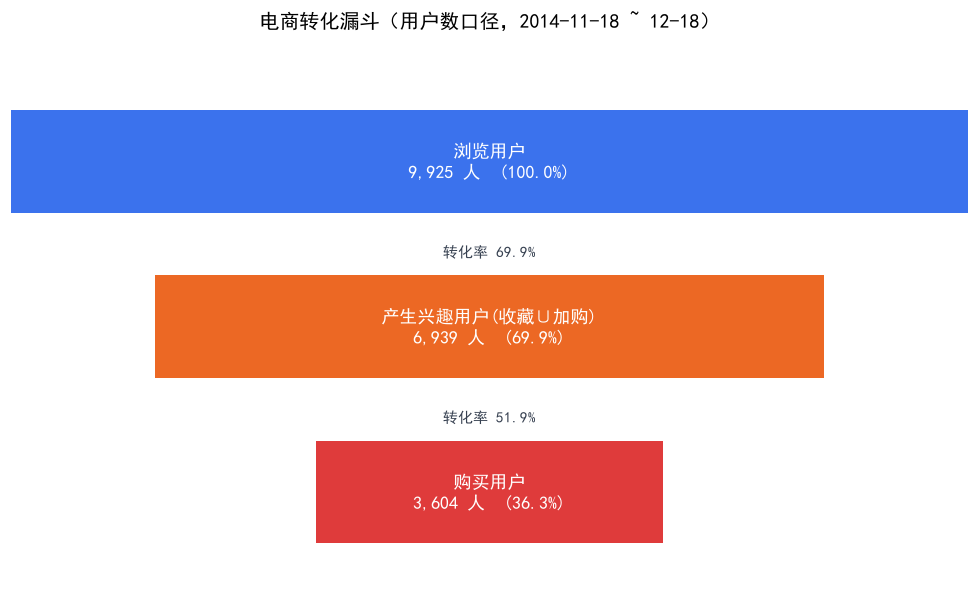

In [4]:
# 漏斗图（用户数口径）
stages = ['浏览用户', '产生兴趣用户(收藏∪加购)', '购买用户']
vals = [u_pv, u_int, u_buy]
colors = ['#2563eb', '#ea580c', '#dc2626']
fig, ax = plt.subplots(figsize=(9, 5.5))
widths = [1.0] + [v / vals[0] for v in vals[1:]]
for i, (s, v, w, c) in enumerate(zip(stages, vals, widths, colors)):
    left = (1 - w) / 2
    ax.barh(2 - i, w, left=left, height=.62, color=c, alpha=.9) #2-i 用来控制每个漏斗条放在 y 轴哪个位置
    ax.text(.5, 2 - i, f'{s}\n{v:,} 人  ({v/vals[0]:.1%})',
            ha='center', va='center', color='white', fontsize=12, fontweight='bold')
    if i > 0:
        ax.text(.5, 2.42 - i, f'转化率 {v/vals[i-1]:.1%}', ha='center', fontsize=10, color='#374151')
ax.set_xlim(0, 1); ax.set_ylim(-.55, 2.75); ax.axis('off')
ax.set_title('电商转化漏斗（用户数口径，2014-11-18 ~ 12-18）', fontsize=13)
fig.tight_layout()
fig.savefig('figures/02_转化漏斗.png', dpi=150, bbox_inches='tight')
plt.show()

### 流失定位

逐环节看"浏览 → 收藏 → 加购 → 购买"细分路径，定位流失最严重的环节。

In [5]:
step = pd.DataFrame({
    '行为次数': [cnt.get(k, 0) for k in ['pv', 'fav', 'cart', 'buy']],
    '独立用户数': [df.loc[df['behavior_type'] == k, 'user_id'].nunique()
                for k in ['pv', 'fav', 'cart', 'buy']],
}, index=['浏览 pv', '收藏 fav', '加购 cart', '购买 buy'])
step['占浏览用户(%)'] = (step['独立用户数'] / u_pv * 100).round(1).astype(str) + '%'  
step

,行为次数,独立用户数,占浏览用户(%)
浏览 pv,881841,9925,100.0%
收藏 fav,28095,5778,58.2%
加购 cart,9494,4567,46.0%
购买 buy,19840,3604,36.3%


In [6]:
# 加购→购买 是经典流失环节：统计加购用户中有多少最终购买（在数据期内）
cart_users = set(df.loc[df['behavior_type'] == 'cart', 'user_id'])
buy_users = set(df.loc[df['behavior_type'] == 'buy', 'user_id'])
cart_buy = len(cart_users & buy_users)
print(f'加购用户 {len(cart_users):,} 人，其中 {cart_buy:,} 人最终购买，'
      f'加购→购买转化率 {cart_buy/len(cart_users):.1%}，'
      f'流失 {len(cart_users)-cart_buy:,} 人（{1-cart_buy/len(cart_users):.1%}）')

加购用户 4,567 人，其中 2,050 人最终购买，加购→购买转化率 44.9%，流失 2,517 人（55.1%）


In [7]:
# 只浏览、最后什么都没做的用户
pv_user=set(df.loc[df['behavior_type'] == 'pv', 'user_id'])
conv_users = set(df.loc[df['behavior_type'].isin(['cart','buy','fav']), 'user_id'])
only_pv_user=pv_user-conv_users
print(f'仅浏览用户 {len(only_pv_user):,} 人，占比 {len(only_pv_user)/len(pv_user):.1%}')


仅浏览用户 2,195 人，占比 22.1%


## 三、双 12 大促效应

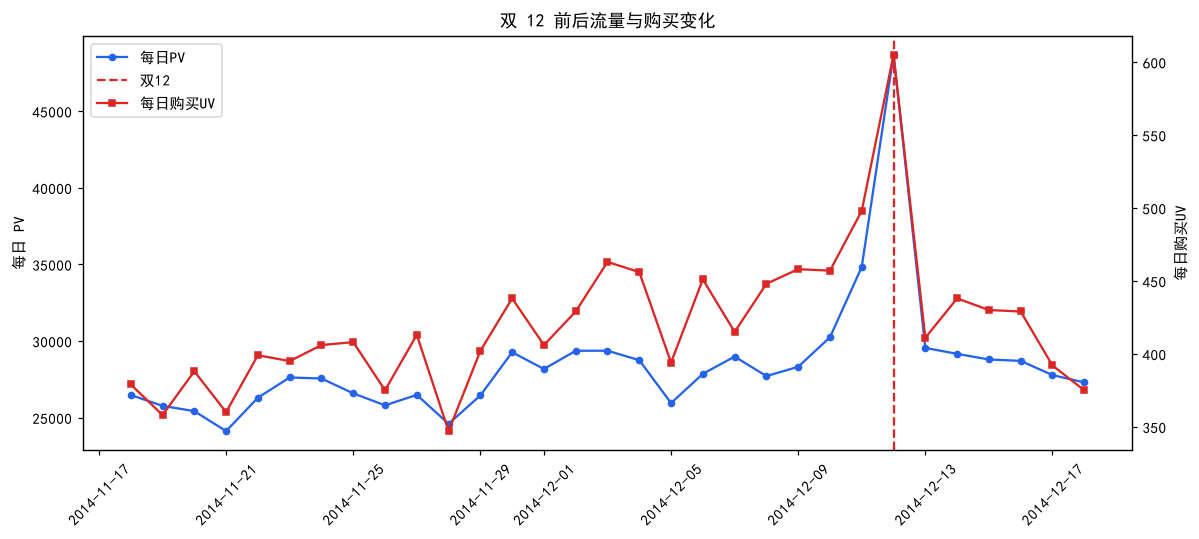

双12当天：PV 48,678（为日常 1.8 倍），购买UV 605


In [8]:
daily_pv = df[df['behavior_type'] == 'pv'].groupby('date').size()
daily_buy_uv = df[df['behavior_type'] == 'buy'].groupby('date')['user_id'].nunique()


fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.plot(daily_pv.index, daily_pv.values, marker='o', ms=4, color='#2563eb', label='每日PV')
ax1.axvline(pd.Timestamp('2014-12-12').date(), color='#dc2626', ls='--', label='双12')
ax1.set_ylabel('每日 PV'); ax1.tick_params(axis='x', rotation=45)
ax2 = ax1.twinx()
ax2.plot(daily_buy_uv.index, daily_buy_uv.values, marker='s', ms=4,
         color='#dc2626', label='每日购买UV')
ax2.set_ylabel('每日购买UV')
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper left')
ax1.set_title('双 12 前后流量与购买变化')
fig.tight_layout()
fig.savefig('figures/02_双12大促效应.png', dpi=150, bbox_inches='tight')
plt.show()

d12 = df[df['date'] == pd.Timestamp('2014-12-12').date()]
print(f"双12当天：PV {len(d12[d12['behavior_type']=='pv']):,}（为日常 "
      f"{len(d12[d12['behavior_type']=='pv'])/daily_pv.drop(pd.Timestamp('2014-12-12').date()).mean():.1f} 倍），"
      f"购买UV {d12[d12['behavior_type']=='buy']['user_id'].nunique():,}")

## 四、MySQL 交叉验证

同样的漏斗统计可用 SQL 完成（先用 `sql/漏斗分析.sql` 建库导数，behavior_type 是数字编码 1=浏览 2=购买 3=收藏 4=加购）：

```sql
-- 用户数口径漏斗
SELECT
  COUNT(DISTINCT CASE WHEN behavior_type = 1     THEN user_id END) AS 浏览用户,
  COUNT(DISTINCT CASE WHEN behavior_type IN (3,4) THEN user_id END) AS 兴趣用户,
  COUNT(DISTINCT CASE WHEN behavior_type = 2     THEN user_id END) AS 购买用户
FROM taobao.user_behavior;
```

实测结果与 Python 完全一致：浏览 9,925 / 兴趣 6,939 / 购买 3,604。

## 五、小结

- 31 天（2014-11-18 ~ 12-18）内 **9,929 名**独立访客产生 88.2 万次浏览，人均约 89 次；
  （注：本数据集为高活跃用户子集，人均浏览与购买占比明显高于全站平均水平，结论侧重相对比较而非绝对水平）
- **用户口径漏斗**：浏览用户 9,925 → 产生兴趣（收藏∪加购）6,939（环比 **69.9%**）→ 购买 3,604（环比 **51.9%**）；
- **纯浏览用户** 2,195 人，占浏览用户的 22.1%，人均浏览 26.7 次——不算"浅尝辄止"，说明有一部分人在认真逛但就是不互动，值得用"收藏引导、加购得券"推他们进入兴趣环节；
- **流失定位**（两条线分工不同）：
  - 流量侧最大缺口在"浏览 → 兴趣"：流失约 30% 用户（约 3,000 人），靠产品侧优化（推荐位、主图、详情页）解决；
  - **"加购 → 购买"仅 44.9%**：加购用户中 2,517 人（55.1%）最终未购买。加购是最强购买意向动作，这部分是高意向用户流失，靠运营侧干预（降价提醒、限时优惠券、弃购召回）性价比最高——即行业经典的"购物车弃置"问题；
- **双 12 大促效应明显**：当天 PV 48,678，约为日常均值的 1.8 倍，购买 UV 605 人，大促对流量和购买均有显著拉动。